# Week 01 · Gridworld: Prediction and Control — 그리드월드: 예측과 제어

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week01_introduction/02_gridworld.ipynb)

슬라이드 *"Gridworld Example: Prediction"*, *"Gridworld: Why is $v_\pi(A) = 8.8$ and not $10$?"*, *"Gridworld Example: Control"*
(Sutton & Barto, Example 3.5 / 3.8, Figure 3.2 / 3.5)을 재현합니다.
균등 랜덤 정책의 가치 함수 $v_\pi$ (예측, prediction)와 최적 가치 함수 $v_*$, 최적 정책 $\pi_*$ (제어, control)를 계산해 슬라이드 숫자와 비교합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이 노트북에서 추가로 쓰는 것
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.patches import FancyArrowPatch

## 1. Gridworld 예측 문제 (Gridworld Example: Prediction)

슬라이드 설정 (Sutton & Barto, Example 3.5):

- $5\times5$ 격자, 행동 $\{N, E, S, W\}$, 결정적 이동
- 격자 밖으로 나가려는 행동: 제자리, 보상 $-1$ / 그 밖의 이동: 보상 $0$
- 특수 상태 $A$: 어떤 행동이든 보상 $+10$을 받고 $A'$로 이동 / $B$: 보상 $+5$, $B'$로 이동
- 할인율 $\gamma = 0.9$, 정책: 균등 랜덤(uniform random), $\pi(a|s) = 0.25$

상태 수가 25개뿐이므로 $v_\pi$는 연립일차방정식 $v_\pi = \mathcal{R}^\pi + \gamma \mathcal{P}^\pi v_\pi$를 풀어 정확히 구할 수 있습니다
(3주차 *"Bellman Expectation Equation (Matrix Form)"* 에서 자세히 다룹니다).

In [2]:
N = 5
GAMMA = 0.9
A_POS, A_PRIME = (0, 1), (4, 1)
B_POS, B_PRIME = (0, 3), (2, 3)
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}


def grid_step(s, a):
    """Deterministic gridworld dynamics of S&B Example 3.5. Returns (next_state, reward)."""
    if s == A_POS:
        return A_PRIME, 10.0
    if s == B_POS:
        return B_PRIME, 5.0
    dr, dc = ACTIONS[a]
    r, c = s[0] + dr, s[1] + dc
    if 0 <= r < N and 0 <= c < N:
        return (r, c), 0.0
    return s, -1.0                     # off the grid: stay, reward -1


def idx(s):
    return s[0] * N + s[1]


# 표 형태: NEXT[i, a] = 다음 상태 번호, REWARD[i, a] = 보상
NEXT = np.zeros((N * N, 4), dtype=int)
REWARD = np.zeros((N * N, 4))
for r in range(N):
    for c in range(N):
        for k, a in enumerate(ACTIONS):
            s2, rew = grid_step((r, c), a)
            NEXT[idx((r, c)), k], REWARD[idx((r, c)), k] = idx(s2), rew


def evaluate_policy_exact(pi, gamma=GAMMA):
    """Solve v = R^pi + gamma P^pi v.  pi[i, a] = probability of action a in state i."""
    n = N * N
    P_pi = np.zeros((n, n))
    for i in range(n):
        for k in range(4):
            P_pi[i, NEXT[i, k]] += pi[i, k]
    R_pi = (pi * REWARD).sum(axis=1)
    return np.linalg.solve(np.eye(n) - gamma * P_pi, R_pi)


pi_random = np.full((N * N, 4), 0.25)
v_random = evaluate_policy_exact(pi_random).reshape(N, N)
print(v_random)

[[ 3.31  8.79  4.43  5.32  1.49]
 [ 1.52  2.99  2.25  1.91  0.55]
 [ 0.05  0.74  0.67  0.36 -0.4 ]
 [-0.97 -0.44 -0.35 -0.59 -1.18]
 [-1.86 -1.35 -1.23 -1.42 -1.98]]


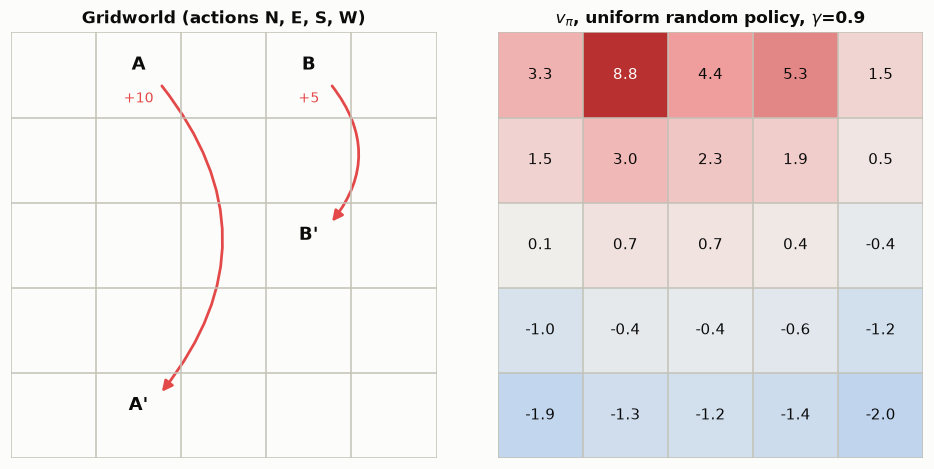

In [3]:
def text_color_on(face_rgba):
    """Black text on light cells, white text on dark cells."""
    r, g, b = face_rgba[:3]
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "#0b0b0b"


def setup_grid_axes(ax, title=None):
    ax.set_xlim(-0.5, N - 0.5)
    ax.set_ylim(N - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.grid(which="minor", color="#c3c2b7", lw=1)
    ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    if title:
        ax.set_title(title)


def draw_values(ax, V, cmap, norm, title=None, fmt="{:.1f}"):
    """Heatmap of a 5x5 value table with the number written in each cell."""
    ax.imshow(V, cmap=cmap, norm=norm)
    for r in range(N):
        for c in range(N):
            ax.text(c, r, fmt.format(V[r, c]), ha="center", va="center", fontsize=10,
                    color=text_color_on(cmap(norm(V[r, c]))))
    setup_grid_axes(ax, title)


def draw_layout(ax, title="Gridworld"):
    """Empty grid with the special states A -> A' (+10) and B -> B' (+5)."""
    ax.imshow(np.zeros((N, N)), cmap=mpl.colors.ListedColormap(["#fcfcfb"]))
    for (r, c), name in [(A_POS, "A"), (A_PRIME, "A'"), (B_POS, "B"), (B_PRIME, "B'")]:
        ax.text(c, r - 0.12, name, ha="center", va="center", fontsize=12, fontweight="bold")
    for (s, s2, lab) in [(A_POS, A_PRIME, "+10"), (B_POS, B_PRIME, "+5")]:
        ax.add_patch(FancyArrowPatch((s[1] + 0.25, s[0] + 0.1), (s2[1] + 0.25, s2[0] - 0.25),
                                     connectionstyle="arc3,rad=-0.4", arrowstyle="-|>",
                                     mutation_scale=14, color=PALETTE[7], lw=1.8))
        ax.text(s[1], s[0] + 0.28, lab, ha="center", va="center", fontsize=9, color=PALETTE[7])
    setup_grid_axes(ax, title)


def draw_policy(ax, action_sets, title=None):
    """Arrows for every action in action_sets[(r, c)] (several arrows = ties)."""
    ax.imshow(np.zeros((N, N)), cmap=mpl.colors.ListedColormap(["#fcfcfb"]))
    for (r, c), acts in action_sets.items():
        for a in acts:
            dr, dc = ACTIONS[a]
            ax.annotate("", xy=(c + 0.38 * dc, r + 0.38 * dr), xytext=(c, r),
                        arrowprops=dict(arrowstyle="-|>", color=PALETTE[1], lw=1.8, mutation_scale=12))
    setup_grid_axes(ax, title)


fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))
draw_layout(axes[0], "Gridworld (actions N, E, S, W)")
vmax = np.abs(v_random).max()
draw_values(axes[1], v_random, DIV_CMAP, TwoSlopeNorm(0, -vmax, vmax), "$v_\\pi$, uniform random policy, $\\gamma$=0.9")
plt.tight_layout()
plt.show()

### 슬라이드와 비교
슬라이드의 표는 소수 첫째 자리로 반올림되어 있으므로 허용 오차는 $0.05$입니다.

In [4]:
SLIDE_V_RANDOM = np.array([
    [ 3.3,  8.8,  4.4,  5.3,  1.5],
    [ 1.5,  3.0,  2.3,  1.9,  0.5],
    [ 0.1,  0.7,  0.7,  0.4, -0.4],
    [-1.0, -0.4, -0.4, -0.6, -1.2],
    [-1.9, -1.3, -1.2, -1.4, -2.0],
])
print("computed (2 decimals):\n", np.round(v_random, 2))
print("slide:\n", SLIDE_V_RANDOM)
print(f"max |computed - slide| = {np.abs(v_random - SLIDE_V_RANDOM).max():.3f}")
assert np.all(np.abs(v_random - SLIDE_V_RANDOM) <= 0.05 + 1e-9)

computed (2 decimals):
 [[ 3.31  8.79  4.43  5.32  1.49]
 [ 1.52  2.99  2.25  1.91  0.55]
 [ 0.05  0.74  0.67  0.36 -0.4 ]
 [-0.97 -0.44 -0.35 -0.59 -1.18]
 [-1.86 -1.35 -1.23 -1.42 -1.98]]
slide:
 [[ 3.3  8.8  4.4  5.3  1.5]
 [ 1.5  3.   2.3  1.9  0.5]
 [ 0.1  0.7  0.7  0.4 -0.4]
 [-1.  -0.4 -0.4 -0.6 -1.2]
 [-1.9 -1.3 -1.2 -1.4 -2. ]]
max |computed - slide| = 0.050


25칸 모두 슬라이드와 일치합니다. 가장자리 칸, 특히 아래쪽 줄은 벽에 부딪혀 $-1$을 자주 받으므로 음수이고,
$A$와 $B$ 주변은 큰 보상 덕분에 양수입니다.

### 가치 = 기대 반환값 (Value Functions)
슬라이드 *"Value Functions"* 의 정의 $v_\pi(s) = \mathbb{E}_\pi[G_t \mid S_t = s]$를 직접 확인해 봅니다.
$A$에서 출발하는 에피소드를 랜덤 정책으로 많이 시뮬레이션하고, 할인된 반환값의 평균을 구합니다
(연속 과제이므로 200스텝에서 자릅니다. $0.9^{200}\cdot 10 \approx 7\times10^{-9}$이라 무시할 수 있습니다).

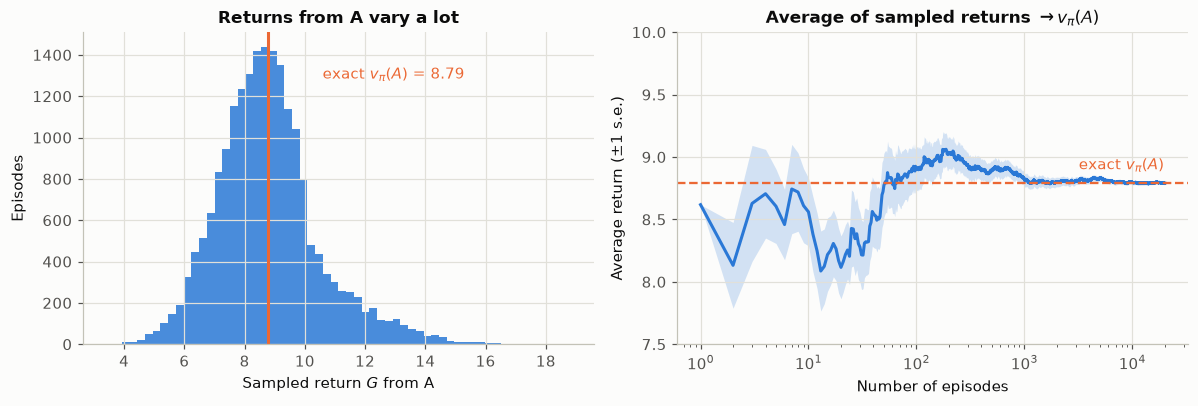

Monte Carlo estimate: 8.790 ± 0.012   exact: 8.789


In [5]:
def sample_returns(start, n_episodes, n_steps, rng, gamma=GAMMA):
    """Discounted returns of n_episodes random-policy trajectories from `start`, truncated at n_steps."""
    s = np.full(n_episodes, idx(start))
    G = np.zeros(n_episodes)
    for t in range(n_steps):
        a = rng.integers(4, size=n_episodes)
        G += gamma**t * REWARD[s, a]
        s = NEXT[s, a]
    return G


G_A = sample_returns(A_POS, n_episodes=20000, n_steps=200, rng=rng)
n = np.arange(1, len(G_A) + 1)
running_mean = np.cumsum(G_A) / n
running_var = np.cumsum(G_A**2) / n - running_mean**2          # variance of the first n returns
running_se = np.sqrt(np.maximum(running_var, 0) / n)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.hist(G_A, bins=60, color=PALETTE[0], alpha=0.85)
ax.axvline(v_random[A_POS], color=PALETTE[1], lw=2)
ax.text(v_random[A_POS] + 1.8, ax.get_ylim()[1] * 0.85, f"exact $v_\\pi(A)$ = {v_random[A_POS]:.2f}", color=PALETTE[1])
ax.set_xlabel("Sampled return $G$ from A")
ax.set_ylabel("Episodes")
ax.set_title("Returns from A vary a lot")
ax = axes[1]
ax.plot(n, running_mean, color=PALETTE[0])
ax.fill_between(n, running_mean - running_se, running_mean + running_se, color=PALETTE[0], alpha=0.2, lw=0)
ax.axhline(v_random[A_POS], color=PALETTE[1], lw=1.5, ls="--")
ax.text(len(n), v_random[A_POS] + 0.08, "exact $v_\\pi(A)$", color=PALETTE[1], ha="right", va="bottom")
ax.set_xscale("log")
ax.set_ylim(7.5, 10)
ax.set_xlabel("Number of episodes")
ax.set_ylabel("Average return (±1 s.e.)")
ax.set_title("Average of sampled returns $\\to v_\\pi(A)$")
plt.tight_layout()
plt.show()

print(f"Monte Carlo estimate: {G_A.mean():.3f} ± {G_A.std() / np.sqrt(len(G_A)):.3f}   exact: {v_random[A_POS]:.3f}")
assert abs(G_A.mean() - v_random[A_POS]) < 4 * G_A.std() / np.sqrt(len(G_A))

한 에피소드의 반환값은 $A'$ 이후의 무작위 경로에 따라 크게 흩어지지만, 평균은 선형 방정식으로 구한 $v_\pi(A)\approx 8.79$로 수렴합니다.
가치 함수는 바로 이 "평균 반환값"입니다.

## 2. 왜 $v_\pi(A) = 8.8$이고 10이 아닌가 (Gridworld: Why is $v_\pi(A) = 8.8$ and not $10$?)

슬라이드의 세 계산을 (a) 슬라이드처럼 반올림된 표 값으로, (b) 정확한 값으로 각각 해 봅니다.

$$v_\pi(A) = 10 + 0.9\,v_\pi(A'), \qquad v_\pi(B) = 5 + 0.9\,v_\pi(B'), \qquad
v_\pi(\text{top-left}) = 0.25\bigl[2(-1 + 0.9\,v_{\text{TL}}) + 0.9\,v_\pi(A) + 0.9\,v_{\text{below}}\bigr]$$

In [6]:
def one_step_backup(V, s, gamma=GAMMA):
    """Right-hand side of the Bellman expectation equation for the random policy at state s."""
    return sum(0.25 * (rew + gamma * V[s2]) for s2, rew in (grid_step(s, a) for a in ACTIONS))


TL, BELOW_TL = (0, 0), (1, 0)
checks = [
    # (label, slide expression result, value in the slide table, state)
    ("v(A)        = 10 + 0.9 v(A')", 10 + 0.9 * (-1.3), 8.8, A_POS),
    ("v(B)        = 5 + 0.9 v(B')", 5 + 0.9 * 0.4, 5.3, B_POS),
    ("v(top-left) = 0.25[...]", 0.25 * (2 * (-1 + 0.9 * 3.3) + (0 + 0.9 * 8.8) + (0 + 0.9 * 1.5)), 3.3, TL),
]
print(f"{'':32} {'slide arithmetic':>17} {'slide table':>12} {'exact':>8}")
for label, slide_calc, slide_table, s in checks:
    exact = one_step_backup(v_random, s)
    print(f"{label:32} {slide_calc:17.2f} {slide_table:12.1f} {exact:8.3f}")
    assert abs(exact - v_random[s]) < 1e-12              # Bellman equation holds exactly
    assert abs(exact - slide_table) <= 0.05 + 1e-9        # matches the slide table

print(f"\nexact v(A') = {v_random[A_PRIME]:.3f}, v(B') = {v_random[B_PRIME]:.3f}")
print(f"cost of landing in A': 0.9 * |v(A')| = {0.9 * abs(v_random[A_PRIME]):.2f}  (slide: 0.9 * 1.3 = 1.17)")

                                  slide arithmetic  slide table    exact
v(A)        = 10 + 0.9 v(A')                  8.83          8.8    8.789
v(B)        = 5 + 0.9 v(B')                   5.36          5.3    5.322
v(top-left) = 0.25[...]                       3.30          3.3    3.309

exact v(A') = -1.345, v(B') = 0.358
cost of landing in A': 0.9 * |v(A')| = 1.21  (slide: 0.9 * 1.3 = 1.17)


- $v_\pi(A)$: 슬라이드 계산 $10 + 0.9\cdot(-1.3) = 8.83$과 정확한 값 $10 + 0.9\cdot(-1.345) = 8.79$ 모두 표의 $8.8$로 반올림됩니다.
  $+10$을 받아도 좋지 않은 자리 $A'$(아래쪽 가장자리)로 떨어지기 때문에 10보다 작습니다.
- $v_\pi(B)$: 슬라이드 계산은 반올림된 $v_\pi(B') = 0.4$를 써서 $5.36$이 나오지만, 정확한 값은 $v_\pi(B') = 0.358$이므로
  $5 + 0.9\cdot 0.358 = 5.32$ — 표의 $5.3$과 일치합니다. (슬라이드의 $5.36$은 반올림된 입력 때문에 생긴 차이로 보입니다.)
- 왼쪽 위 칸: 네 행동의 평균, $3.30$ (정확한 값 $3.31$). 북쪽·서쪽은 벽이라 $-1$을 받고 제자리에 머뭅니다.

## 3. Gridworld 제어 문제 (Gridworld Example: Control)

이제 **모든 정책 중 최선**의 가치 $v_*(s) = \max_\pi v_\pi(s)$와 최적 정책 $\pi_*$를 구합니다.
벨만 최적 방정식(Bellman optimality equation)

$$v_*(s) = \max_a \bigl[r(s,a) + \gamma\, v_*(s')\bigr]$$

을 반복 적용하는 가치 반복(value iteration)으로 풉니다(4주차에 자세히 다룹니다). 최적 행동은 위 식에서 최댓값을 주는 행동이며,
동점인 행동은 모두 표시합니다.

value iteration converged after 286 sweeps
[[21.98 24.42 21.98 19.42 17.48]
 [19.78 21.98 19.78 17.8  16.02]
 [17.8  19.78 17.8  16.02 14.42]
 [16.02 17.8  16.02 14.42 12.98]
 [14.42 16.02 14.42 12.98 11.68]]


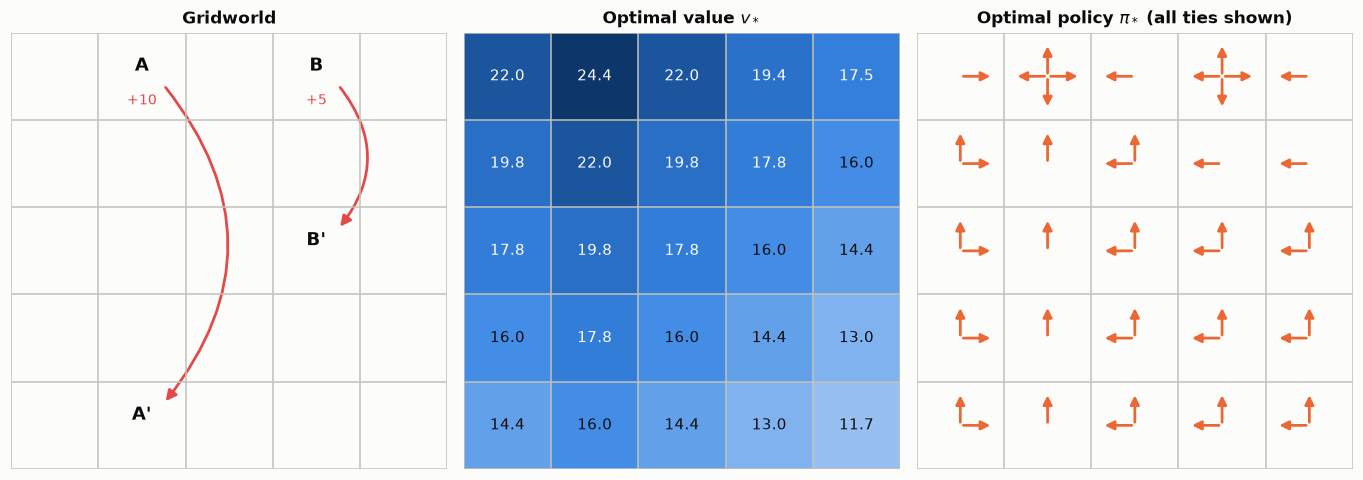

In [7]:
def value_iteration(gamma=GAMMA, tol=1e-12):
    """v_{k+1}(s) = max_a [r(s,a) + gamma v_k(s')] until convergence. Returns v and the number of sweeps."""
    v = np.zeros(N * N)
    for k in range(1, 10_000):
        q = REWARD + gamma * v[NEXT]            # q[i, a]
        v_new = q.max(axis=1)
        if np.abs(v_new - v).max() < tol:
            return v_new, k
        v = v_new


def optimal_action_sets(v, gamma=GAMMA, tie_tol=1e-6):
    """All actions whose one-step look-ahead value is within tie_tol of the best one."""
    q = REWARD + gamma * v[NEXT]
    names = list(ACTIONS)
    return {(r, c): {names[k] for k in range(4) if q[idx((r, c)), k] >= q[idx((r, c))].max() - tie_tol}
            for r in range(N) for c in range(N)}


v_star_flat, sweeps = value_iteration()
v_star = v_star_flat.reshape(N, N)
pi_star = optimal_action_sets(v_star_flat)
print(f"value iteration converged after {sweeps} sweeps")
print(np.round(v_star, 2))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))
draw_layout(axes[0], "Gridworld")
draw_values(axes[1], v_star, SEQ_CMAP, Normalize(v_star.min() - 3, v_star.max()), "Optimal value $v_*$")
draw_policy(axes[2], pi_star, "Optimal policy $\\pi_*$ (all ties shown)")
plt.tight_layout()
plt.show()

### 슬라이드와 비교

In [8]:
SLIDE_V_STAR = np.array([
    [22.0, 24.4, 22.0, 19.4, 17.5],
    [19.8, 22.0, 19.8, 17.8, 16.0],
    [17.8, 19.8, 17.8, 16.0, 14.4],
    [16.0, 17.8, 16.0, 14.4, 13.0],
    [14.4, 16.0, 14.4, 13.0, 11.7],
])
ALL = {"N", "E", "S", "W"}
SLIDE_PI_STAR = {  # 슬라이드 tikz 화살표를 (row, col) 로 옮김
    (0, 0): {"E"}, (0, 1): ALL, (0, 2): {"W"}, (0, 3): ALL, (0, 4): {"W"},
    (1, 0): {"N", "E"}, (1, 1): {"N"}, (1, 2): {"N", "W"}, (1, 3): {"W"}, (1, 4): {"W"},
    (2, 0): {"N", "E"}, (2, 1): {"N"}, (2, 2): {"N", "W"}, (2, 3): {"N", "W"}, (2, 4): {"N", "W"},
    (3, 0): {"N", "E"}, (3, 1): {"N"}, (3, 2): {"N", "W"}, (3, 3): {"N", "W"}, (3, 4): {"N", "W"},
    (4, 0): {"N", "E"}, (4, 1): {"N"}, (4, 2): {"N", "W"}, (4, 3): {"N", "W"}, (4, 4): {"N", "W"},
}
print(f"max |v* - slide| = {np.abs(v_star - SLIDE_V_STAR).max():.3f}")
assert np.all(np.abs(v_star - SLIDE_V_STAR) <= 0.05 + 1e-9)
assert pi_star == SLIDE_PI_STAR
print("all 25 values and all 25 arrow sets of pi* match the slide")
print(f"v*(A) = {v_star[A_POS]:.4f} = 10 / (1 - 0.9^5) = {10 / (1 - 0.9**5):.4f}")

max |v* - slide| = 0.023
all 25 values and all 25 arrow sets of pi* match the slide
v*(A) = 24.4194 = 10 / (1 - 0.9^5) = 24.4194


$v_*$와 $\pi_*$ 모두 슬라이드와 일치합니다. 최적 정책은 "$A$로 가서 $+10$을 받고, $A'$에서 다시 위로 4칸 올라와 $A$로" 를 반복합니다.
그래서 $v_*(A) = 10 + 0.9^5\, v_*(A)$, 즉 $v_*(A) = 10/(1-0.9^5) \approx 24.4$입니다.
$B$는 $+5$로 작고 $B'$에서 $A$까지 거리도 있어서, $B$ 바로 옆 칸조차 $B$ 대신 $A$ 쪽(서쪽)을 택합니다.

## 직접 해보기

1. `GAMMA`를 $0.5$나 $0.99$로 바꿔 1절과 3절을 다시 실행해 보세요. $\gamma$가 작으면 $v_*$ 근처에서 $B$를 택하는 칸이 생기나요?
2. `grid_step`에서 $B$의 보상을 $+5$에서 $+8$로 바꾸면 $\pi_*$의 화살표가 어떻게 바뀌나요?
3. 1절의 몬테카를로 추정에서 `n_steps`를 $10$으로 줄이면 추정값이 정확한 $v_\pi(A)$에서 얼마나 벗어나나요? (잘린 부분의 크기는 약 $\gamma^{10}$ 비율입니다.)
4. 균등 랜덤 대신 "항상 북쪽" 같은 결정적 정책의 $v_\pi$를 `evaluate_policy_exact`로 구해 $v_*$와 비교해 보세요.